In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [25]:

import numpy as np
import matplotlib.pyplot as plt

dirt = np.linspace(0, 10, 101)
load = np.linspace(0.5, 8, 101)
water = np.linspace(0, 100, 101)


def triangular_mf(x, a, b, c):
    x = np.asarray(x, dtype=float)

    if not (a <= b <= c):
        raise ValueError("Expected a <= b <= c")

    # Handle left-shoulder and right-shoulder triangles
    if a == b:
        left = np.ones_like(x)
    else:
        left = (x - a) / (b - a)

    if b == c:
        right = np.ones_like(x)
    else:
        right = (c - x) / (c - b)

    membership = np.minimum(left, right)
    membership = np.clip(membership, 0, 1)

    # Ensure the peak has membership 1
    membership = np.where(x == b, 1.0, membership)

    return membership


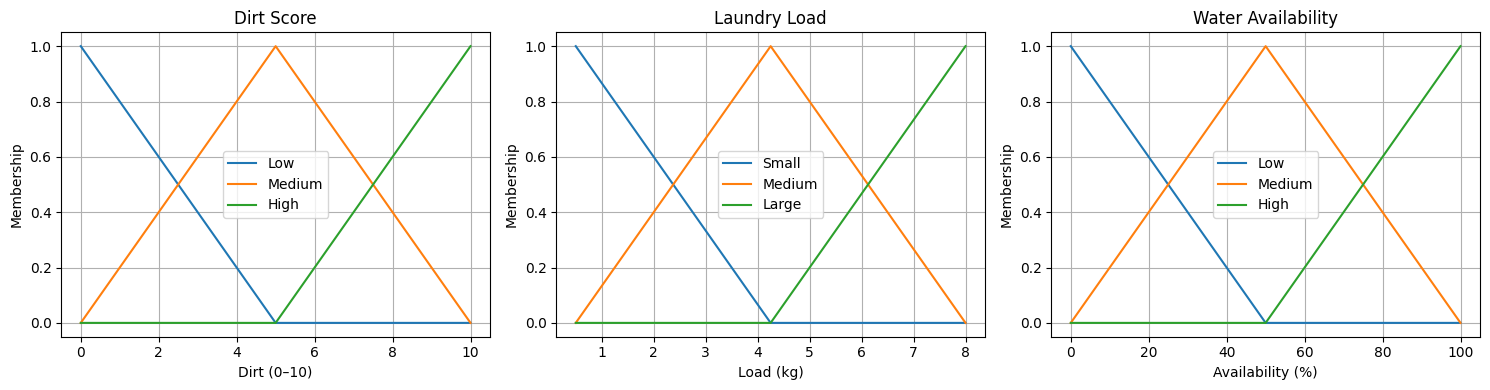

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Triangular membership function
def triangular_mf(x, a, b, c):
    x = np.asarray(x, dtype=float)

    if not (a <= b <= c):
        raise ValueError("Expected a <= b <= c")

    if a == b:
        left = np.ones_like(x)
    else:
        left = (x - a) / (b - a)

    if b == c:
        right = np.ones_like(x)
    else:
        right = (c - x) / (c - b)

    membership = np.minimum(left, right)
    membership = np.clip(membership, 0, 1)
    membership = np.where(x == b, 1.0, membership)

    return membership


# Input ranges
dirt = np.linspace(0, 10, 101)
load = np.linspace(0.5, 8, 101)
water = np.linspace(0, 100, 101)

# Dirt membership functions
dirt_low = triangular_mf(dirt, -5, 0, 5)
dirt_medium = triangular_mf(dirt, 0, 5, 10)
dirt_high = triangular_mf(dirt, 5, 10, 15)

# Load membership functions
load_small = triangular_mf(load, -3.25, 0.5, 4.25)
load_medium = triangular_mf(load, 0.5, 4.25, 8)
load_large = triangular_mf(load, 4.25, 8, 11.75)

# Water availability membership functions
water_low = triangular_mf(water, -50, 0, 50)
water_medium = triangular_mf(water, 0, 50, 100)
water_high = triangular_mf(water, 50, 100, 150)

# Plot membership functions
plt.figure(figsize=(15, 4))

# Dirt score
plt.subplot(1, 3, 1)
plt.plot(dirt, dirt_low, label="Low")
plt.plot(dirt, dirt_medium, label="Medium")
plt.plot(dirt, dirt_high, label="High")
plt.title("Dirt Score")
plt.xlabel("Dirt (0–10)")
plt.ylabel("Membership")
plt.legend()
plt.grid(True)

# Load size
plt.subplot(1, 3, 2)
plt.plot(load, load_small, label="Small")
plt.plot(load, load_medium, label="Medium")
plt.plot(load, load_large, label="Large")
plt.title("Laundry Load")
plt.xlabel("Load (kg)")
plt.ylabel("Membership")
plt.legend()
plt.grid(True)

# Water availability
plt.subplot(1, 3, 3)
plt.plot(water, water_low, label="Low")
plt.plot(water, water_medium, label="Medium")
plt.plot(water, water_high, label="High")
plt.title("Water Availability")
plt.xlabel("Availability (%)")
plt.ylabel("Membership")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [27]:

# Output ranges
wash_time = np.linspace(15, 90, 151)   # minutes
water_litres = np.linspace(20, 100, 161)  # litres
detergent = np.linspace(10, 100, 181)  # ml
spin_rpm = np.linspace(400, 1400, 201)  # RPM

# Wash time membership functions
time_short = triangular_mf(wash_time, 15, 15, 52.5)
time_normal = triangular_mf(wash_time, 15, 52.5, 90)
time_long = triangular_mf(wash_time, 52.5, 90, 90)

# Water usage membership functions
water_usage_low = triangular_mf(water_litres, 20, 20, 60)
water_usage_medium = triangular_mf(water_litres, 20, 60, 100)
water_usage_high = triangular_mf(water_litres, 60, 100, 100)

# Detergent membership functions
detergent_low = triangular_mf(detergent, 10, 10, 55)
detergent_medium = triangular_mf(detergent, 10, 55, 100)
detergent_high = triangular_mf(detergent, 55, 100, 100)

# Spin speed membership functions
spin_low = triangular_mf(spin_rpm, 400, 400, 900)
spin_medium = triangular_mf(spin_rpm, 400, 900, 1400)
spin_high = triangular_mf(spin_rpm, 900, 1400, 1400)

print("Output membership functions created successfully!")


Output membership functions created successfully!


In [28]:

def fuzzify(value, x, membership):
    """Return the membership degree for a crisp input."""
    return float(np.interp(value, x, membership))


def activate_rule(*degrees):
    """Mamdani AND operator: minimum membership."""
    return min(degrees)


def aggregate_rules(activations, output_sets):
    """Combine clipped output sets using maximum."""
    combined = np.zeros_like(next(iter(output_sets.values()))[0])

    for name, strength in activations.items():
        x, membership = output_sets[name]
        combined = np.maximum(combined, np.minimum(strength, membership))

    return combined


def centroid_defuzzify(x, membership):
    """Convert an aggregated fuzzy output to a crisp value."""
    area = np.sum(membership)

    if area == 0:
        raise ValueError("No fuzzy rule fired; cannot defuzzify.")

    return float(np.sum(x * membership) / area)


print("Mamdani inference helper functions created successfully!")


Mamdani inference helper functions created successfully!


In [29]:

def washing_controller(dirt_score, load_kg, fabric_type,
                       water_availability_pct):
    # Validate inputs
    if not 0 <= dirt_score <= 10:
        raise ValueError("Dirt score must be between 0 and 10.")
    if not 0.5 <= load_kg <= 8:
        raise ValueError("Load must be between 0.5 and 8 kg.")
    if not 0 <= water_availability_pct <= 100:
        raise ValueError("Water availability must be between 0 and 100%.")
    if fabric_type not in ["delicate", "cotton", "synthetic", "heavy"]:
        raise ValueError("Invalid fabric type.")

    # Fuzzify inputs
    dl = fuzzify(dirt_score, dirt, dirt_low)
    dm = fuzzify(dirt_score, dirt, dirt_medium)
    dh = fuzzify(dirt_score, dirt, dirt_high)

    ls = fuzzify(load_kg, load, load_small)
    lm = fuzzify(load_kg, load, load_medium)
    ll = fuzzify(load_kg, load, load_large)

    wl = fuzzify(water_availability_pct, water, water_low)
    wm = fuzzify(water_availability_pct, water, water_medium)
    wh = fuzzify(water_availability_pct, water, water_high)

    # Rule strengths
    time_short_strength = max(min(dl, ls), dl * 0.0)
    time_normal_strength = dm
    time_long_strength = max(dh, min(dh, ll))

    detergent_low_strength = dl
    detergent_medium_strength = max(dm, min(dh, ls))
    detergent_high_strength = max(min(dh, ll), dh)


    # Water usage rules: consider availability and load
    water_low_strength = max(
        wl,
        min(wm, ls)
    )

    water_medium_strength = max(
        min(wm, lm),
        min(wh, ls)
    )

    water_high_strength = max(
        min(wh, ll),
        min(wm, ll)
    )


    # Fabric-based spin settings
    if fabric_type == "delicate":
        spin_low_strength, spin_medium_strength, spin_high_strength = 1, 0, 0
    elif fabric_type == "cotton":
        spin_low_strength, spin_medium_strength, spin_high_strength = 0, 0, 1
    elif fabric_type == "synthetic":
        spin_low_strength, spin_medium_strength, spin_high_strength = 0, 1, 0
    else:
        spin_low_strength, spin_medium_strength, spin_high_strength = 0, 0, 1

    # Aggregate and defuzzify outputs
    time_membership = np.maximum.reduce([
        np.minimum(time_short_strength, time_short),
        np.minimum(time_normal_strength, time_normal),
        np.minimum(time_long_strength, time_long)
    ])

    water_membership = np.maximum.reduce([
        np.minimum(water_low_strength, water_usage_low),
        np.minimum(water_medium_strength, water_usage_medium),
        np.minimum(water_high_strength, water_usage_high)
    ])

    detergent_membership = np.maximum.reduce([
        np.minimum(detergent_low_strength, detergent_low),
        np.minimum(detergent_medium_strength, detergent_medium),
        np.minimum(detergent_high_strength, detergent_high)
    ])

    spin_membership = np.maximum.reduce([
        np.minimum(spin_low_strength, spin_low),
        np.minimum(spin_medium_strength, spin_medium),
        np.minimum(spin_high_strength, spin_high)
    ])

    return {
        "wash_time_min": round(centroid_defuzzify(wash_time, time_membership), 2),
        "water_litre": round(centroid_defuzzify(water_litres, water_membership), 2),
        "detergent_ml": round(centroid_defuzzify(detergent, detergent_membership), 2),
        "spin_rpm": round(centroid_defuzzify(spin_rpm, spin_membership), 2)
    }

print("Initial fuzzy washing controller created successfully!")


Initial fuzzy washing controller created successfully!


In [30]:

test_cases = [
    (2, 2.0, "cotton", 100, "FUZZY-001"),
    (5, 4.0, "synthetic", 60, "FUZZY-002"),
    (9, 7.0, "heavy", 100, "FUZZY-003"),
    (5, 2.0, "delicate", 80, "FUZZY-004"),
    (7, 5.0, "cotton", 20, "FUZZY-005"),
    (0, 0.5, "delicate", 0, "FUZZY-006"),
    (10, 8.0, "heavy", 100, "FUZZY-007"),
    (11, 9.0, "unknown", 110, "FUZZY-008")
]

results = []

for dirt_score, load_kg, fabric, water_pct, test_id in test_cases:
    try:
        output = washing_controller(
            dirt_score, load_kg, fabric, water_pct
        )
        results.append({
            "Test ID": test_id,
            "Status": "PASS - Accepted",
            **output
        })
    except ValueError as error:
        results.append({
            "Test ID": test_id,
            "Status": f"PASS - Rejected: {error}",
            "wash_time_min": None,
            "water_litre": None,
            "detergent_ml": None,
            "spin_rpm": None
        })

results_df = pd.DataFrame(results)
display(results_df)


,Test ID,Status,wash_time_min,water_litre,detergent_ml,spin_rpm
0,FUZZY-001,PASS - Accepted,45.76,60.00,46.95,1235.0
1,FUZZY-002,PASS - Accepted,52.50,59.89,55.00,900.0
2,FUZZY-003,PASS - Accepted,65.63,86.06,70.72,1235.0
3,FUZZY-004,PASS - Accepted,52.50,56.88,55.00,565.0
4,FUZZY-005,PASS - Accepted,55.43,53.95,58.49,1235.0
5,FUZZY-006,PASS - Accepted,27.33,33.17,24.83,565.0
6,FUZZY-007,PASS - Accepted,77.67,86.83,85.17,1235.0
7,FUZZY-008,PASS - Rejected: Dirt score must be between 0 ...,NaN,NaN,NaN,NaN


In [31]:

# Check the controller on three different scenarios

scenarios = [
    (2, 2.0, "cotton", 100),
    (9, 7.0, "heavy", 100),
    (5, 2.0, "delicate", 80)
]

for case in scenarios:
    result = washing_controller(*case)
    print("\nInput:", case)
    print("Recommendation:", result)



Input: (2, 2.0, 'cotton', 100)
Recommendation: {'wash_time_min': 45.76, 'water_litre': 60.0, 'detergent_ml': 46.95, 'spin_rpm': 1235.0}

Input: (9, 7.0, 'heavy', 100)
Recommendation: {'wash_time_min': 65.63, 'water_litre': 86.06, 'detergent_ml': 70.72, 'spin_rpm': 1235.0}

Input: (5, 2.0, 'delicate', 80)
Recommendation: {'wash_time_min': 52.5, 'water_litre': 56.88, 'detergent_ml': 55.0, 'spin_rpm': 565.0}


In [32]:

# Check invalid inputs are rejected

invalid_cases = [
    (11, 2.0, "cotton", 100),
    (5, 9.0, "cotton", 100),
    (5, 2.0, "unknown", 100),
    (5, 2.0, "cotton", 110)
]

for case in invalid_cases:
    try:
        washing_controller(*case)
        print("FAIL: Invalid input was accepted:", case)
    except ValueError as error:
        print("PASS: Invalid input rejected:", case, "|", error)


PASS: Invalid input rejected: (11, 2.0, 'cotton', 100) | Dirt score must be between 0 and 10.
PASS: Invalid input rejected: (5, 9.0, 'cotton', 100) | Load must be between 0.5 and 8 kg.
PASS: Invalid input rejected: (5, 2.0, 'unknown', 100) | Invalid fabric type.
PASS: Invalid input rejected: (5, 2.0, 'cotton', 110) | Water availability must be between 0 and 100%.


In [33]:

# Step 3 Validation Summary

validation_summary = {
    "Invalid input tests": 4,
    "Invalid inputs rejected": 4,
    "Validation status": "PASS",
    "Controller status": "Initial prototype - further tuning required"
}

for key, value in validation_summary.items():
    print(f"{key}: {value}")


Invalid input tests: 4
Invalid inputs rejected: 4
Validation status: PASS
Controller status: Initial prototype - further tuning required


In [34]:

# Restore the input ranges used by the membership functions
dirt = np.linspace(0, 10, 101)
load = np.linspace(0.5, 8, 101)
water = np.linspace(0, 100, 101)

print("Dirt shape:", dirt.shape)
print("Load shape:", load.shape)
print("Water shape:", water.shape)


Dirt shape: (101,)
Load shape: (101,)
Water shape: (101,)


In [35]:

# Restore input ranges
dirt = np.linspace(0, 10, 101)
load = np.linspace(0.5, 8, 101)
water = np.linspace(0, 100, 101)

print("Dirt:", dirt.shape)
print("Load:", load.shape)
print("Water:", water.shape)


Dirt: (101,)
Load: (101,)
Water: (101,)


In [36]:

print("Dirt range:", dirt.shape)
print("Load range:", load.shape)
print("Test membership:", fuzzify(2, dirt, dirt_low))


Dirt range: (101,)
Load range: (101,)
Test membership: 0.6


In [37]:

test_cases = [
    (2, 2.0, "cotton", 100, "FUZZY-001"),
    (5, 4.0, "synthetic", 60, "FUZZY-002"),
    (9, 7.0, "heavy", 100, "FUZZY-003"),
    (5, 2.0, "delicate", 80, "FUZZY-004"),
    (7, 5.0, "cotton", 20, "FUZZY-005"),
    (0, 0.5, "delicate", 0, "FUZZY-006"),
    (10, 8.0, "heavy", 100, "FUZZY-007"),
    (11, 9.0, "unknown", 110, "FUZZY-008")
]

for dirt_score, load_kg, fabric, water_pct, test_id in test_cases:
    try:
        result = washing_controller(
            dirt_score, load_kg, fabric, water_pct
        )
        print(test_id, "ACCEPTED:", result)
    except ValueError as error:
        print(test_id, "REJECTED:", error)


FUZZY-001 ACCEPTED: {'wash_time_min': 45.76, 'water_litre': 60.0, 'detergent_ml': 46.95, 'spin_rpm': 1235.0}
FUZZY-002 ACCEPTED: {'wash_time_min': 52.5, 'water_litre': 59.89, 'detergent_ml': 55.0, 'spin_rpm': 900.0}
FUZZY-003 ACCEPTED: {'wash_time_min': 65.63, 'water_litre': 86.06, 'detergent_ml': 70.72, 'spin_rpm': 1235.0}
FUZZY-004 ACCEPTED: {'wash_time_min': 52.5, 'water_litre': 56.88, 'detergent_ml': 55.0, 'spin_rpm': 565.0}
FUZZY-005 ACCEPTED: {'wash_time_min': 55.43, 'water_litre': 53.95, 'detergent_ml': 58.49, 'spin_rpm': 1235.0}
FUZZY-006 ACCEPTED: {'wash_time_min': 27.33, 'water_litre': 33.17, 'detergent_ml': 24.83, 'spin_rpm': 565.0}
FUZZY-007 ACCEPTED: {'wash_time_min': 77.67, 'water_litre': 86.83, 'detergent_ml': 85.17, 'spin_rpm': 1235.0}
FUZZY-008 REJECTED: Dirt score must be between 0 and 10.


In [38]:

# Step 3: Baseline Washing Model

baseline_presets = {
    "delicate": {
        "wash_time_min": 30,
        "water_litre": 40,
        "detergent_ml": 30,
        "spin_rpm": 600
    },
    "cotton": {
        "wash_time_min": 45,
        "water_litre": 60,
        "detergent_ml": 50,
        "spin_rpm": 1000
    },
    "synthetic": {
        "wash_time_min": 35,
        "water_litre": 50,
        "detergent_ml": 40,
        "spin_rpm": 800
    },
    "heavy": {
        "wash_time_min": 60,
        "water_litre": 75,
        "detergent_ml": 60,
        "spin_rpm": 1200
    }
}


def baseline_controller(dirt_score, load_kg, fabric_type,
                        water_availability_pct):
    if not 0 <= dirt_score <= 10:
        raise ValueError("Dirt score must be between 0 and 10.")
    if not 0.5 <= load_kg <= 8.0:
        raise ValueError("Load must be between 0.5 and 8 kg.")
    if fabric_type not in baseline_presets:
        raise ValueError("Invalid fabric type.")
    if not 0 <= water_availability_pct <= 100:
        raise ValueError("Water availability must be between 0 and 100%.")

    return baseline_presets[fabric_type].copy()


print("Baseline controller created successfully!")


Baseline controller created successfully!


In [39]:

comparison_cases = [
    (2, 2.0, "cotton", 100, "FUZZY-001"),
    (5, 4.0, "synthetic", 60, "FUZZY-002"),
    (9, 7.0, "heavy", 100, "FUZZY-003"),
    (5, 2.0, "delicate", 80, "FUZZY-004"),
    (7, 5.0, "cotton", 20, "FUZZY-005"),
    (0, 0.5, "delicate", 0, "FUZZY-006"),
    (10, 8.0, "heavy", 100, "FUZZY-007")
]

comparison_rows = []

for dirt_score, load_kg, fabric, water_pct, test_id in comparison_cases:
    baseline = baseline_controller(
        dirt_score, load_kg, fabric, water_pct
    )
    fuzzy = washing_controller(
        dirt_score, load_kg, fabric, water_pct
    )

    comparison_rows.append({
        "Test ID": test_id,
        "Fabric": fabric,
        "Baseline Time": baseline["wash_time_min"],
        "Fuzzy Time": fuzzy["wash_time_min"],
        "Baseline Water": baseline["water_litre"],
        "Fuzzy Water": fuzzy["water_litre"],
        "Baseline Detergent": baseline["detergent_ml"],
        "Fuzzy Detergent": fuzzy["detergent_ml"],
        "Baseline RPM": baseline["spin_rpm"],
        "Fuzzy RPM": fuzzy["spin_rpm"]
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(2))


,Test ID,Fabric,Baseline Time,Fuzzy Time,Baseline Water,Fuzzy Water,Baseline Detergent,Fuzzy Detergent,Baseline RPM,Fuzzy RPM
0,FUZZY-001,cotton,45,45.76,60,60.00,50,46.95,1000,1235.0
1,FUZZY-002,synthetic,35,52.50,50,59.89,40,55.00,800,900.0
2,FUZZY-003,heavy,60,65.63,75,86.06,60,70.72,1200,1235.0
3,FUZZY-004,delicate,30,52.50,40,56.88,30,55.00,600,565.0
4,FUZZY-005,cotton,45,55.43,60,53.95,50,58.49,1000,1235.0
5,FUZZY-006,delicate,30,27.33,40,33.17,30,24.83,600,565.0
6,FUZZY-007,heavy,60,77.67,75,86.83,60,85.17,1200,1235.0


In [40]:

comparison_df.to_csv("step3_baseline_vs_fuzzy.csv", index=False)
print("Comparison report saved successfully!")
print("Rows:", len(comparison_df))


Comparison report saved successfully!
Rows: 7


In [41]:
invalid_tests = [
    (11, 2.0, "cotton", 50, "Invalid dirt"),
    (5, 9.0, "cotton", 50, "Invalid load"),
    (5, 2.0, "unknown", 50, "Invalid fabric"),
    (5, 2.0, "cotton", 110, "Invalid water"),
]

passed = 0

for dirt_score, load_kg, fabric, water_pct, name in invalid_tests:
    try:
        washing_controller(dirt_score, load_kg, fabric, water_pct)
        print("FAIL:", name, "was accepted")
    except ValueError:
        print("PASS:", name, "was rejected")
        passed += 1

print(f"\nInvalid input tests: {len(invalid_tests)}")
print(f"Invalid inputs rejected: {passed}")
print("Validation status:", "PASS" if passed == len(invalid_tests) else "FAIL")

PASS: Invalid dirt was rejected
PASS: Invalid load was rejected
PASS: Invalid fabric was rejected
PASS: Invalid water was rejected

Invalid input tests: 4
Invalid inputs rejected: 4
Validation status: PASS


In [42]:
import urllib.request
import sys

url = "https://raw.githubusercontent.com/AdityaTripathi077/Smart-Washing-Machine-Optimizer/main/src/fuzzy_controller.py"

urllib.request.urlretrieve(url, "/content/fuzzy_controller.py")
sys.path.insert(0, "/content")

from fuzzy_controller import washing_controller

print(washing_controller(2, 2.0, "cotton", 100))

try:
    washing_controller(11, 2.0, "cotton", 50)
except ValueError as e:
    print("Invalid input rejected:", e)

{'wash_time_min': 40.31, 'water_litre': 86.83, 'detergent_ml': 39.45, 'spin_rpm': 900.0}
Invalid input rejected: Dirt score must be between 0 and 10.


In [43]:
from fuzzy_controller import washing_controller

print(washing_controller(2, 2.0, "cotton", 100))

try:
    washing_controller(11, 2.0, "cotton", 50)
except ValueError as e:
    print("Invalid input rejected:", e)

{'wash_time_min': 40.31, 'water_litre': 86.83, 'detergent_ml': 39.45, 'spin_rpm': 900.0}
Invalid input rejected: Dirt score must be between 0 and 10.


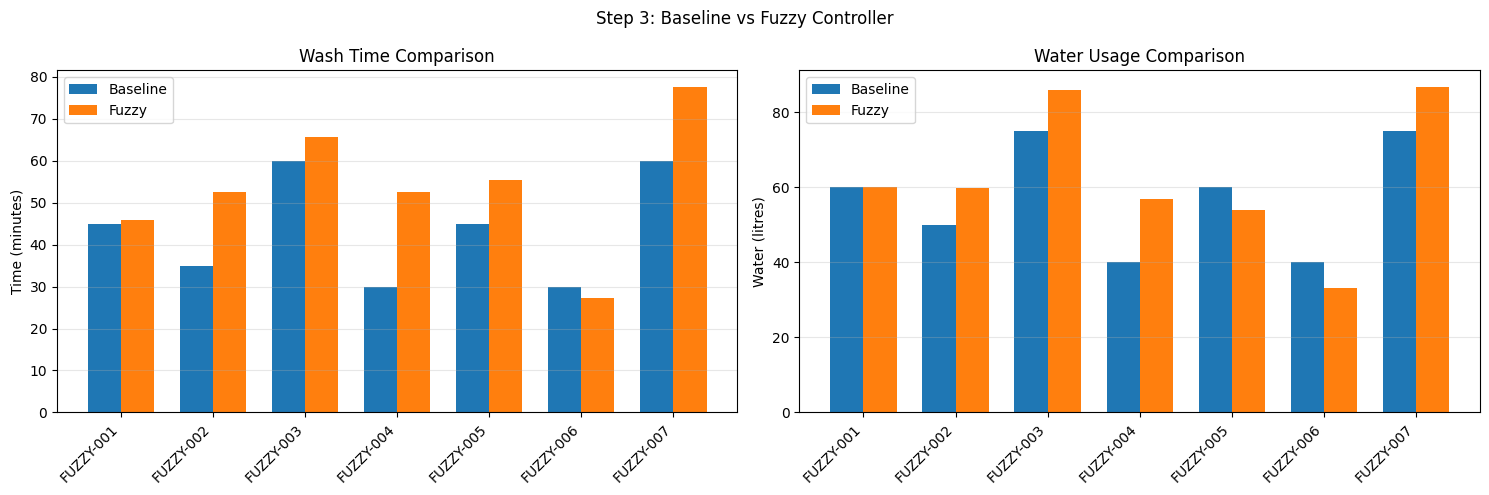

Chart saved to: results/step3_baseline_vs_fuzzy.png


In [44]:

import os
import matplotlib.pyplot as plt
import numpy as np

# Results from the existing Step 3 comparison report
test_ids = [
    "FUZZY-001", "FUZZY-002", "FUZZY-003",
    "FUZZY-004", "FUZZY-005", "FUZZY-006",
    "FUZZY-007"
]

baseline_time = [45, 35, 60, 30, 45, 30, 60]
fuzzy_time = [45.76, 52.50, 65.63, 52.50, 55.43, 27.33, 77.67]

baseline_water = [60, 50, 75, 40, 60, 40, 75]
fuzzy_water = [60.00, 59.89, 86.06, 56.88, 53.95, 33.17, 86.83]

x = np.arange(len(test_ids))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Wash time comparison
axes[0].bar(x - width/2, baseline_time, width, label="Baseline")
axes[0].bar(x + width/2, fuzzy_time, width, label="Fuzzy")
axes[0].set_title("Wash Time Comparison")
axes[0].set_ylabel("Time (minutes)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(test_ids, rotation=45, ha="right")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Water usage comparison
axes[1].bar(x - width/2, baseline_water, width, label="Baseline")
axes[1].bar(x + width/2, fuzzy_water, width, label="Fuzzy")
axes[1].set_title("Water Usage Comparison")
axes[1].set_ylabel("Water (litres)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(test_ids, rotation=45, ha="right")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle("Step 3: Baseline vs Fuzzy Controller")
plt.tight_layout()

# Save the chart
os.makedirs("results", exist_ok=True)
output_path = "results/step3_baseline_vs_fuzzy.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved to:", output_path)
